# MolScope Quickstart: End-to-End Conformational Analysis

[![Open in JupyterLab](https://img.shields.io/badge/Launch-JupyterLab-orange.svg)](https://jupyter.org)
[![Python 3.10+](https://img.shields.io/badge/python-3.10+-blue.svg)](https://www.python.org/)
[![License: MIT](https://img.shields.io/badge/License-MIT-green.svg)](https://opensource.org/licenses/MIT)

Welcome to **MolScope**! This interactive tutorial walks you through an end-to-end conformational analysis of the canonical fast-folding **HP35 Villin Headpiece** (PDB: `2RJY`).

### What You Will Learn
1. **Initialize a Study**: Set up a stateful study workspace with on-the-fly Periodic Boundary Condition (PBC) imaging.
2. **Multi-Family Featurization**: Extract residue-residue contacts, Cα distances, DSSP secondary structure, and sidechain dihedrals.
3. **Dimensionality Reduction**: Project conformational dynamics onto **TICA** (slow kinetic transitions) and **Contact Kernel PCA** (CKPCA non-linear RKHS embeddings).
4. **State Discovery (DPA)**: Discover metastable conformational free energy basins without arbitrary cluster counts using **Density Peak Advanced**.
5. **Free Energy Landscapes**: Compute and visualize 2D Potential of Mean Force ($\Delta G$ in kcal/mol) surfaces with detected energy minima.
6. **Explainable AI**: Extract transparent, human-readable Boolean decision rules that structurally define each macrostate.
7. **3D Molecular Hotspots**: Map residue importances directly onto PDB B-factors with one-click PyMOL and ChimeraX visualizers.
8. **Interactive Dashboard**: Explore the self-contained offline HTML report (`report.html`).


## 1. Imports and Environment Setup


In [1]:
%matplotlib inline
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Image

# Import MolScope's high-level interactive Study API
from molscope.api import Study

print(f"Python: {sys.version.split()[0]}")


Python: 3.13.13


## 2. Locate System Data and Initialize Study

We use the HP35 Villin Headpiece (596 atoms, 35 residues, 3 $\alpha$-helices forming a hydrophobic core).
We will locate the trajectory (`simulation_run1.xtc`) and topology (`protein.pdb`).


In [2]:
# Automatically locate tutorial dataset with fallback to test fixtures
data_candidates = [
    Path("data/2RJY"),
    Path("../data/2RJY"),
    Path("../../data/2RJY"),
    Path("/Users/nirav/Docs/mdxplain study/mdxplain/data/2RJY"),
    Path("../mdxplain study/mdxplain/data/2RJY"),
]

data_dir = next(
    (p for p in data_candidates if (p / "protein.pdb").is_file() and (p / "simulation_run1.xtc").is_file()),
    None,
)

if data_dir is not None:
    topology_file = data_dir / "protein.pdb"
    trajectory_file = data_dir / "simulation_run1.xtc"
    print(f"Loaded 2RJY Villin Headpiece dataset from: {data_dir}")
else:
    fixture_candidates = [
        Path("tests/fixtures/1A22.pdb"),
        Path("../tests/fixtures/1A22.pdb"),
        Path("../../tests/fixtures/1A22.pdb"),
    ]
    fixture_path = next((p for p in fixture_candidates if p.is_file()), None)
    if fixture_path is None:
        raise FileNotFoundError("Could not find tutorial dataset or fallback fixture 1A22.pdb.")
    topology_file = fixture_path
    trajectory_file = fixture_path
    print(f"Notice: 2RJY dataset not found. Falling back to test fixture: {topology_file}")

print(f"Topology:   {topology_file}")
print(f"Trajectory: {trajectory_file}")


Loaded 2RJY Villin Headpiece dataset from: data/2RJY
Topology:   data/2RJY/protein.pdb
Trajectory: data/2RJY/simulation_run1.xtc


Now we initialize a stateful `Study` workspace.
The study manages data provenance, cached feature extractions, kinetic coordinates, and export directories.


In [3]:
import MDAnalysis as mda

out_dir = Path("results/quickstart_2rjy")
out_dir.mkdir(parents=True, exist_ok=True)

# For 1-frame static test fixtures, generate a multi-frame demonstration trajectory
# so TICA, DPA, and FES can execute seamlessly
actual_trajectories = [trajectory_file]
u_traj = mda.Universe(str(topology_file), str(trajectory_file))
if len(u_traj.trajectory) <= 1:
    fallback_traj = out_dir / "fallback_trajectory.pdb"
    if not fallback_traj.is_file():
        rng = np.random.default_rng(42)
        with mda.Writer(str(fallback_traj), len(u_traj.atoms)) as w:
            for _ in range(50):
                u_traj.atoms.positions += rng.normal(0, 0.02, size=u_traj.atoms.positions.shape)
                w.write(u_traj)
    actual_trajectories = [fallback_traj]

study = Study(
    project_id="2rjy_quickstart",
    out_dir=out_dir,
)

# Register the Villin Headpiece system
study.add_system(
    system_id="villin_headpiece",
    topology=topology_file,
    trajectories=actual_trajectories,
    condition_label="wild_type_300K",
)

# Configure Periodic Boundary Condition (PBC) unwrapping and centering
study.configure_imaging(unwrap=True, center_selection="protein", wrap=False)
print("Study initialized successfully.")


Study initialized successfully.


## 3. Multi-Family Biophysical Featurization

Unlike tools limited to simple pairwise contacts, MolScope extracts multiple complementary biophysical feature families:
- **`protein.ca_distances_contacts`**: Pairwise Cα distances and binary contact graphs ($\le 8.0$ Å).
- **`protein.secondary_structure_dssp`**: Fractions of $\alpha$-helix, $\beta$-sheet, and coil.
- **`protein.sidechain_torsions`**: Circular $\sin/\cos$ rotamers for key hydrophobic core residues (Phe47, Phe51, Phe58).


In [4]:
# Selection policy: HP35 Villin Headpiece has 35 residues; for large fallback proteins,
# restrict to resid 1-35 to maintain bounded contact pair complexity
ca_selection = "protein and name CA and resid 1-35" if "1A22" in str(topology_file) else "protein and name CA"

study.configure_features(
    plugins=[
        "protein.ca_distances_contacts",
        "protein.secondary_structure_dssp",
        "protein.sidechain_torsions",
    ],
    plugin_parameters={
        "protein.ca_distances_contacts": {
            "selection": ca_selection,
            "contact_cutoff_angstrom": 8.0,
            "max_pairs": 3000,
        },
        "protein.secondary_structure_dssp": {
            "per_residue": False,
        },
        "protein.sidechain_torsions": {
            "residue_ids": [47, 51, 58],  # Hydrophobic core rotamers
        },
    },
    generic_parameters={
        "frame_stride": 5,   # Subsample stride 5 (2,000 frames from 10,001)
        "max_frames": 2000,
    },
)

# Extract features
print("Extracting multi-family biophysical features...")
study.run(extract_only=True)

features = study.get_features()
manifest = study.get_manifest()

print(f"Extracted {features.shape[1]} features across {features.shape[0]} trajectory frames.")
features.iloc[:5, :6]


Extracting multi-family biophysical features...


Extracted 3800 features across 2000 trajectory frames.


,GEOM_global_radius_gyration,GEOM_global_asphericity,DYN_kabsch_rmsd_to_first_frame,CA_DISTANCE_angstrom__SYSTEM__LEU_13__SYSTEM__PHE_16,CA_CONTACT__SYSTEM__LEU_13__SYSTEM__PHE_16,CA_DISTANCE_angstrom__SYSTEM__LEU_13__SYSTEM__PRO_17
0,11.581391,0.326638,0.000000,10.069449,0.0,13.457719
1,11.797519,0.338045,1.567659,9.956236,0.0,13.388718
2,11.781858,0.369249,1.840184,10.187958,0.0,13.870471
3,11.665135,0.306391,1.867317,10.182665,0.0,13.604512
4,11.584204,0.335556,1.750731,9.652403,0.0,13.043964


## 4. Dimensionality Reduction: Variational TICA & Contact KPCA

To understand conformational transitions, we project high-dimensional coordinates onto:
1. **TICA (Time-lagged Independent Component Analysis)**: Finds the slowest kinetic relaxation modes by solving the generalized eigenvalue problem $C_\tau v_i = \lambda_i C_0 v_i$.
2. **Contact Kernel PCA (CKPCA)**: Non-linear kernel projection ($k(x, y) = \exp(-\gamma \|x-y\|^2)$) capturing non-linear contact manifolds.


In [5]:
# 1. Fit Variational TICA (lag time tau = 2 frames = 1.0 ns)
tica_result = study.run_tica(lag_time=2, components=5)

print("TICA Implied Timescales (ps):")
for i, ts in enumerate(tica_result.implied_timescales[:4], 1):
    print(f"  Mode {i}: {ts:.1f} ps")

# 2. Fit Contact Kernel PCA
ckpca_result = study.run_contact_kpca(n_components=4)
print(f"Contact KPCA computed {ckpca_result.coordinates.shape[1]} non-linear components.")


TICA Implied Timescales (ps):
  Mode 1: 6928294.6 ps
  Mode 2: 117289.7 ps
  Mode 3: 80847.8 ps
  Mode 4: 69011.0 ps


Contact KPCA computed 19 non-linear components.


In [6]:
# Inspect kinetic coordinates
tica_coords = tica_result.coordinates
tica_coords.head()


,trajectory_id,replica_id,ensemble_id,system_id,frame_index,frame_order,time_ps,topology_path,trajectory_path,metadata_replica_condition,...,TIC_1,TIC1,TIC_2,TIC2,TIC_3,TIC3,TIC_4,TIC4,TIC_5,TIC5
0,villin_headpiece:default_ensemble:rep_01,rep_01,villin_headpiece:default_ensemble,villin_headpiece,0,0,0.0,/Users/nirav/Docs/molscope/data/2RJY/protein.pdb,/Users/nirav/Docs/molscope/data/2RJY/simulatio...,wild_type_300K,...,0.647424,0.647424,-0.429970,-0.429970,0.572976,0.572976,-0.601770,-0.601770,0.144892,0.144892
1,villin_headpiece:default_ensemble:rep_01,rep_01,villin_headpiece:default_ensemble,villin_headpiece,5,1,500.0,/Users/nirav/Docs/molscope/data/2RJY/protein.pdb,/Users/nirav/Docs/molscope/data/2RJY/simulatio...,wild_type_300K,...,0.612735,0.612735,-0.355567,-0.355567,0.281593,0.281593,-0.690990,-0.690990,0.160080,0.160080
2,villin_headpiece:default_ensemble:rep_01,rep_01,villin_headpiece:default_ensemble,villin_headpiece,10,2,1000.0,/Users/nirav/Docs/molscope/data/2RJY/protein.pdb,/Users/nirav/Docs/molscope/data/2RJY/simulatio...,wild_type_300K,...,0.849018,0.849018,-0.396008,-0.396008,0.670875,0.670875,-0.893477,-0.893477,0.293338,0.293338
3,villin_headpiece:default_ensemble:rep_01,rep_01,villin_headpiece:default_ensemble,villin_headpiece,15,3,1500.0,/Users/nirav/Docs/molscope/data/2RJY/protein.pdb,/Users/nirav/Docs/molscope/data/2RJY/simulatio...,wild_type_300K,...,0.881304,0.881304,-0.561661,-0.561661,0.446213,0.446213,-0.899500,-0.899500,0.388791,0.388791
4,villin_headpiece:default_ensemble:rep_01,rep_01,villin_headpiece:default_ensemble,villin_headpiece,20,4,2000.0,/Users/nirav/Docs/molscope/data/2RJY/protein.pdb,/Users/nirav/Docs/molscope/data/2RJY/simulatio...,wild_type_300K,...,0.935123,0.935123,-0.583267,-0.583267,0.661530,0.661530,-1.118649,-1.118649,0.275186,0.275186


## 5. Non-Parametric State Discovery: Density Peak Advanced (DPA)

MolScope employs **Density Peak Advanced (DPA)** clustering directly on the TICA kinetic manifold.
DPA automatically finds high-density free energy basins ($\rho$) and saddle-point barriers ($\delta$) **without requiring the user to specify an arbitrary number of clusters ($k$)**.


In [7]:
# Cluster on the slowest kinetic coordinates (TIC1 vs TIC2)
dpa_result = study.cluster_dpa(coordinate_name="TICA", z_score=2.0, min_clusters=2)

print(f"Discovered {dpa_result.n_clusters} conformational macrostates.")
for state_id, pop in dpa_result.state_populations.items():
    pct = (pop / len(features)) * 100
    print(f"  State {state_id}: {pop:4d} frames ({pct:5.1f}%)")


Discovered 6 conformational macrostates.
  State 0:  704 frames ( 35.2%)
  State 1:  531 frames ( 26.6%)
  State 2:  184 frames (  9.2%)
  State 3:  276 frames ( 13.8%)
  State 4:  203 frames ( 10.2%)
  State 5:  102 frames (  5.1%)


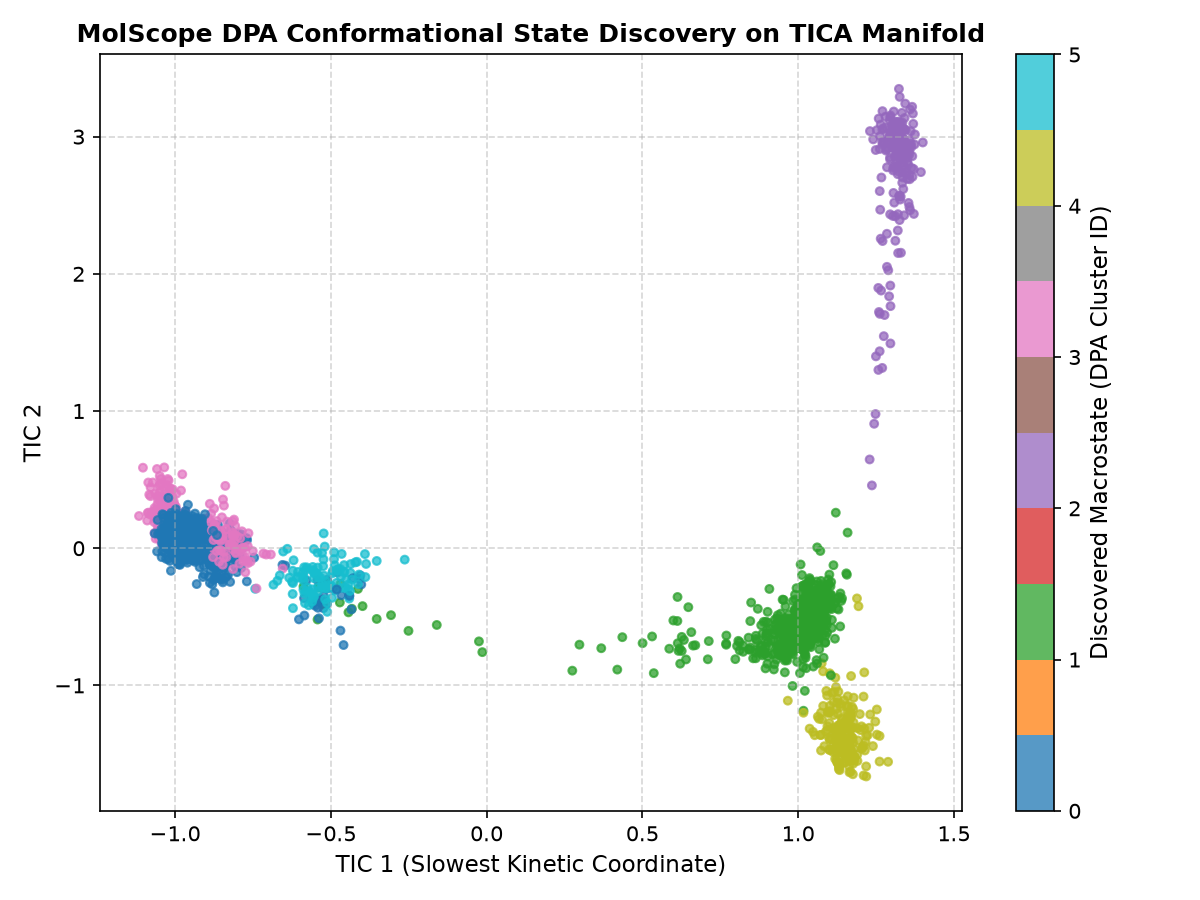

In [8]:
# Plot DPA clusters on the TICA reaction coordinates
fig, ax = plt.subplots(figsize=(8, 6))
scatter = ax.scatter(
    tica_coords["TIC1"],
    tica_coords["TIC2"],
    c=dpa_result.assignments["Cluster"],
    cmap="tab10",
    s=14,
    alpha=0.75,
)
cbar = plt.colorbar(scatter, ax=ax)
cbar.set_label("Discovered Macrostate (DPA Cluster ID)", fontsize=11)
ax.set_xlabel("TIC 1 (Slowest Kinetic Coordinate)", fontsize=11)
ax.set_ylabel("TIC 2", fontsize=11)
ax.set_title("MolScope DPA Conformational State Discovery on TICA Manifold", fontsize=12, fontweight="bold")
ax.grid(True, linestyle="--", alpha=0.5)
plt.tight_layout()

# Save figure and display inline
dpa_plot_path = out_dir / "dpa_clusters_tica.png"
fig.savefig(dpa_plot_path, dpi=150)
plt.close(fig)
display(Image(filename=str(dpa_plot_path)))


## 6. 2D Free Energy Surface (FES) Landscape

We compute the potential of mean force:
$$\Delta G(x, y) = -k_B T \ln P(x, y)$$
and identify local thermodynamic energy basins ($B_1, B_2, \dots$).


findfont: Failed to find font weight medium, now using 400.


findfont: Failed to find font weight medium, now using 400.


Static FES plot:      results/quickstart_2rjy/free_energy/fes_TIC1_TIC2.png
Interactive HTML FES: results/quickstart_2rjy/free_energy/fes_TIC1_TIC2.html
Detected 5 free energy basins:


,basin_id,x,y,free_energy,probability
0,1,-0.989943,0.090392,0.000000,5.697932
1,2,1.022573,-0.511049,0.496152,2.479008
2,3,1.173512,-1.413212,0.919708,1.218215
3,4,1.324451,2.997361,0.994640,1.074328
4,5,-0.537127,-0.310569,1.200964,0.760034


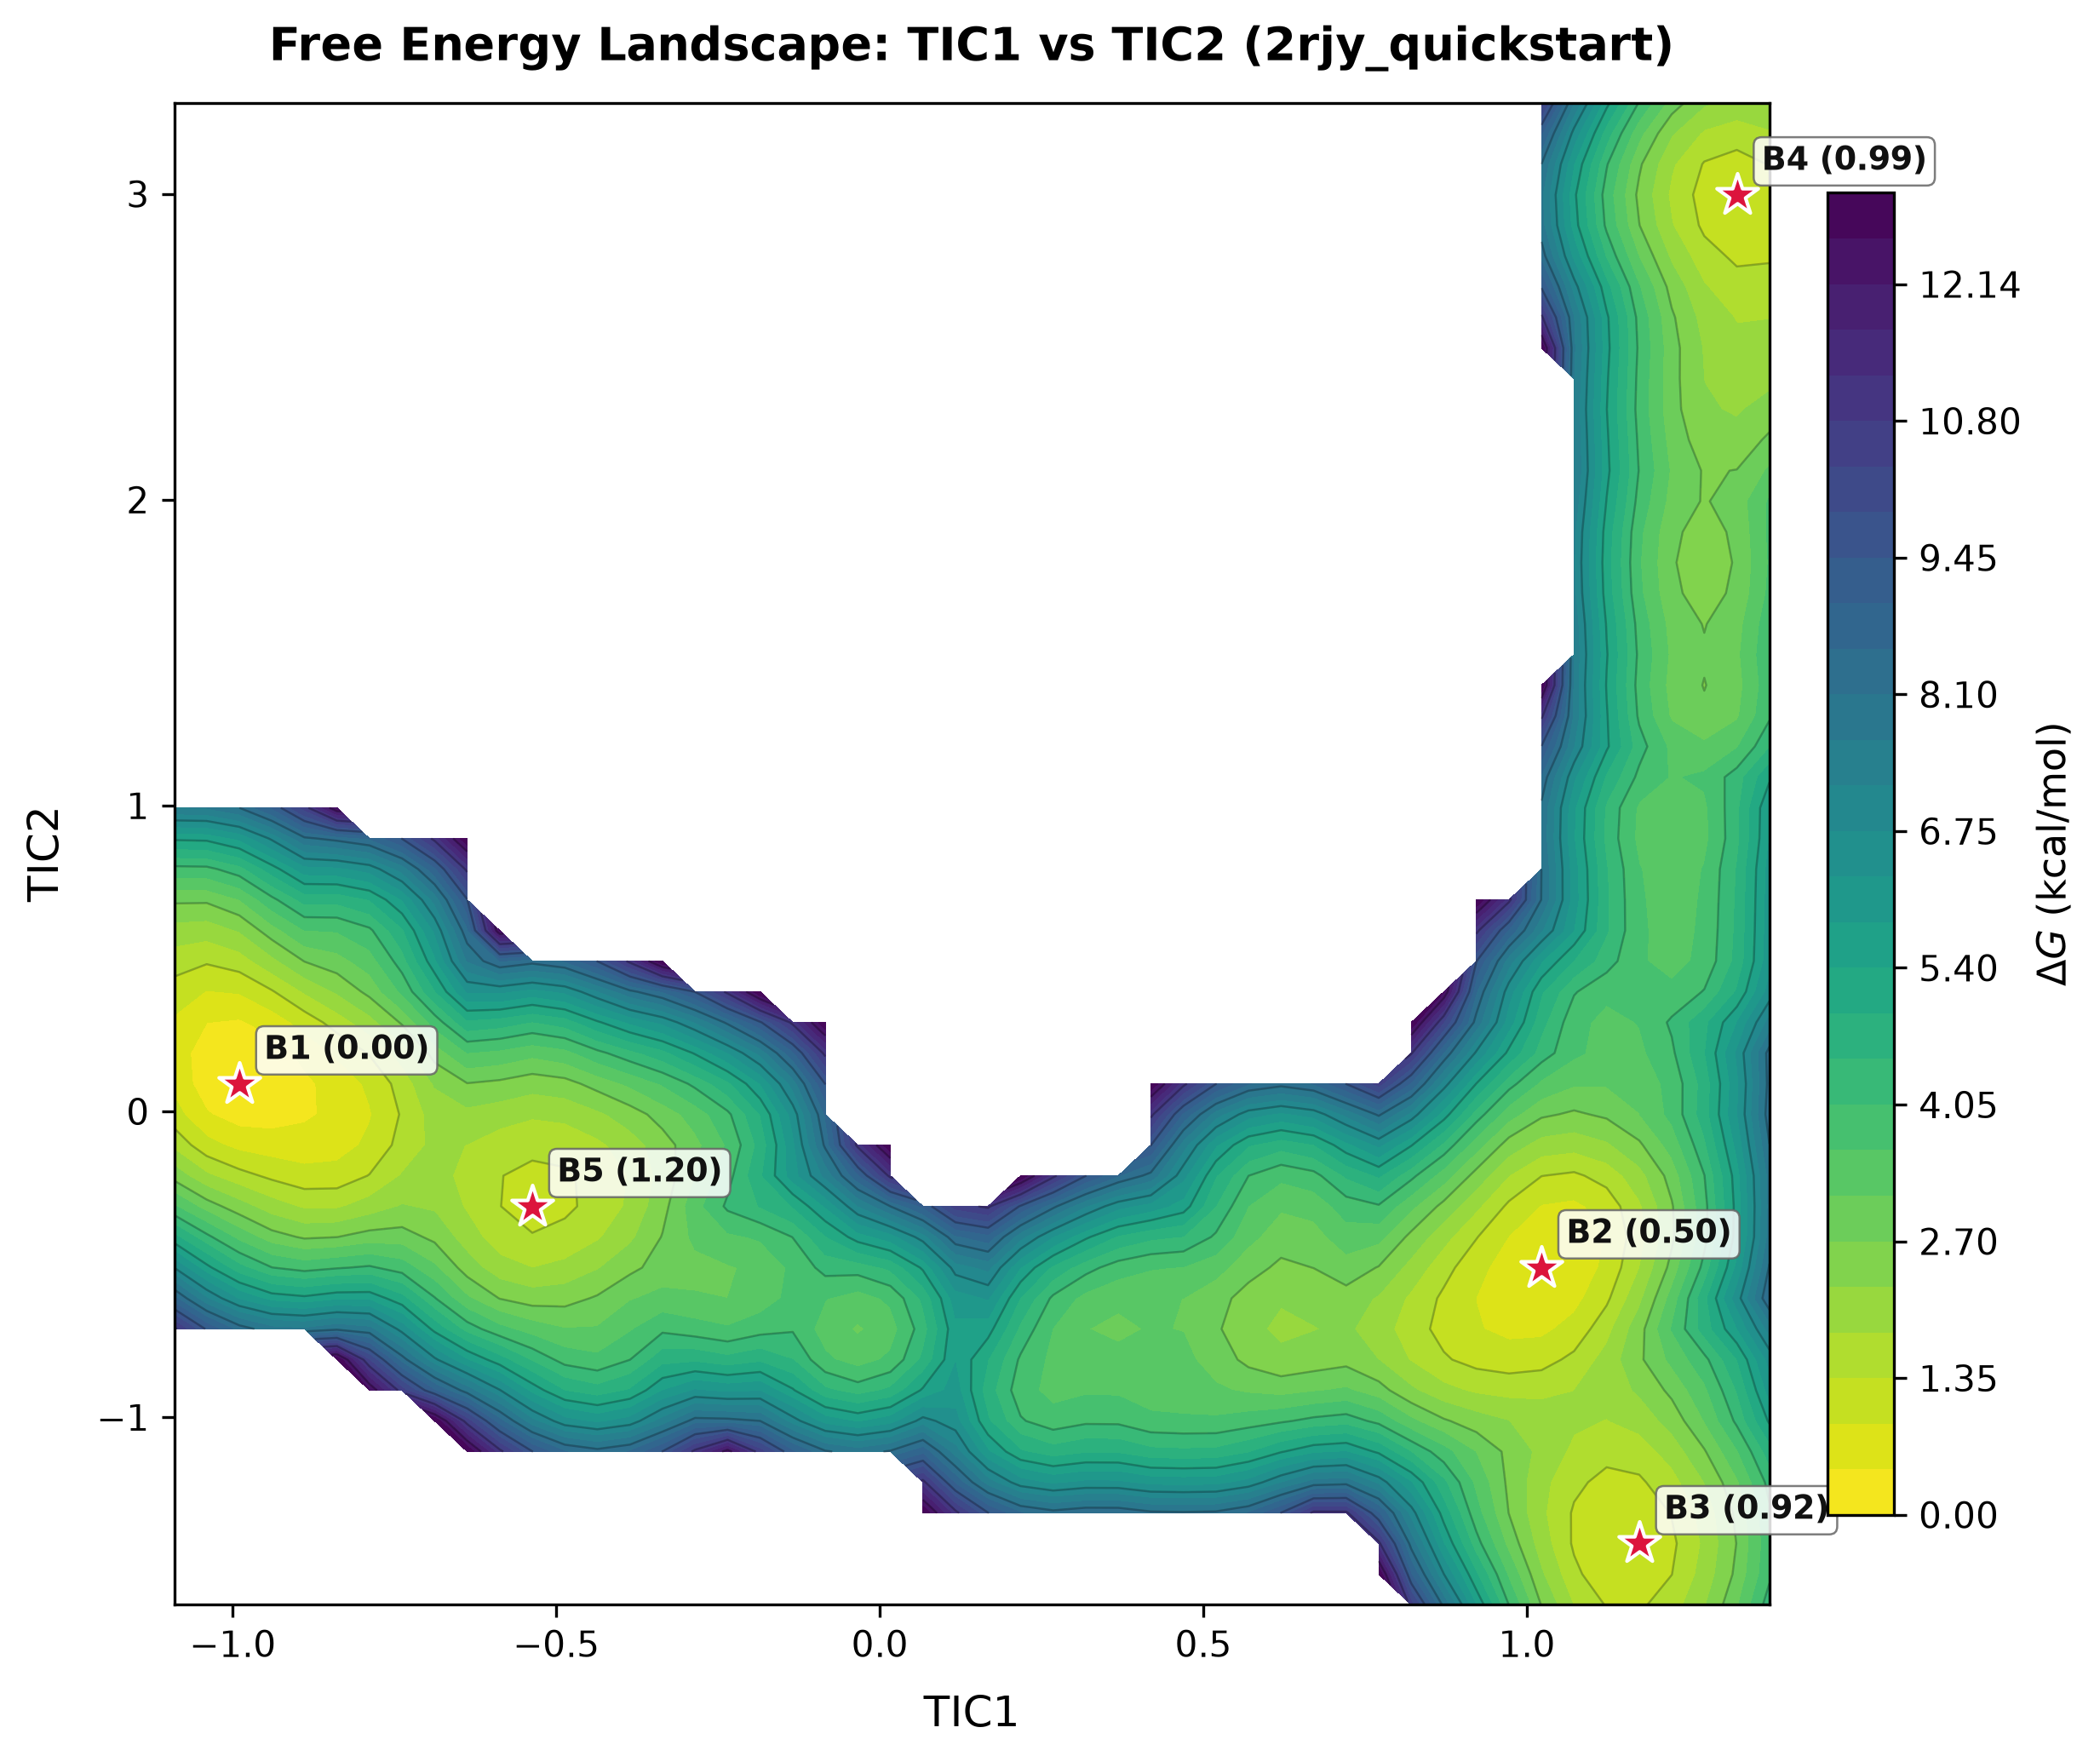

In [9]:
fes_out = study.plot_free_energy_landscape(
    dim1="TIC1",
    dim2="TIC2",
    temperature_k=300.0,
    units="kcal/mol",
    bins=50,
    smooth=1.0,
)

print(f"Static FES plot:      {fes_out['static_plot']}")
print(f"Interactive HTML FES: {fes_out['interactive_plot']}")
print(f"Detected {len(fes_out['basins'])} free energy basins:")
display(fes_out["basins"])
display(Image(filename=str(fes_out["static_plot"])))


## 7. Explainable AI: Decision Tree Boolean Rule Extraction

Rather than treating conformational states as black boxes, MolScope extracts human-interpretable Boolean decision rules:
$$\text{IF } [\text{Feature}_A \le \theta_A] \text{ AND } [\text{Feature}_B > \theta_B] \implies \text{Macrostate } S_k$$


In [10]:
explainer = study.explain_clusters(
    clustering_name="dpa",
    max_depth=3,
    min_samples_leaf=10,
)

print("Extracted Boolean Biophysical Rules for Discovered States:")
for rule in explainer.rules:
    print()
    print(f"--- State {rule.cluster_id} ({rule.cluster_name}) ---")
    print(f"  Precision: {rule.precision * 100:.1f}% | Recall: {rule.recall * 100:.1f}% | Support: {rule.support_fraction * 100:.1f}%")
    print(f"  Rule: {rule.simplified_rule_text()}")

display(explainer.rules_dataframe().head(8))


Extracted Boolean Biophysical Rules for Discovered States:

--- State 0 (Macrostate 0) ---
  Precision: 98.8% | Recall: 92.5% | Support: 98.8%
  Rule: CA_DISTANCE_angstrom__SYSTEM__ALA_26__SYSTEM__GLY_32 > 16.22 Å AND CA_DISTANCE_angstrom__SYSTEM__GLU_27__SYSTEM__PRO_35 > 11.07 Å AND CA_DISTANCE_angstrom__SYSTEM__ALA_26__SYSTEM__ARG_31 > 13.87 Å

--- State 0 (Macrostate 0) ---
  Precision: 100.0% | Recall: 1.7% | Support: 100.0%
  Rule: CA_DISTANCE_angstrom__SYSTEM__ALA_26__SYSTEM__GLY_32 <= 16.22 Å AND CA_DISTANCE_angstrom__SYSTEM__ASN_23__SYSTEM__LEU_61 <= 23.76 Å

--- State 0 (Macrostate 0) ---
  Precision: 54.5% | Recall: 0.9% | Support: 54.5%
  Rule: CA_DISTANCE_angstrom__SYSTEM__ALA_26__SYSTEM__GLY_32 <= 16.22 Å AND CA_DISTANCE_angstrom__SYSTEM__ASN_23__SYSTEM__LEU_61 > 23.76 Å AND CA_DISTANCE_angstrom__SYSTEM__VAL_20__SYSTEM__ALA_25 > 11.56 Å

--- State 1 (Macrostate 1) ---
  Precision: 94.1% | Recall: 95.3% | Support: 94.1%
  Rule: CA_DISTANCE_angstrom__SYSTEM__ALA_25__SYSTEM__

,Cluster,Rule_Index,Rule,Precision,Recall,F1,Support,Total_Samples,Condition_Count
0,cluster_0,1,IF CA_DISTANCE_angstrom__SYSTEM__ALA_26__SYSTE...,0.987860,0.924716,0.955246,651,659,3
1,cluster_0,2,IF CA_DISTANCE_angstrom__SYSTEM__ALA_26__SYSTE...,1.000000,0.017045,0.033520,12,12,2
2,cluster_0,3,IF CA_DISTANCE_angstrom__SYSTEM__ALA_26__SYSTE...,0.545455,0.008523,0.016783,6,11,3
3,cluster_1,1,IF CA_DISTANCE_angstrom__SYSTEM__ALA_25__SYSTE...,0.940520,0.952919,0.946679,506,538,3
4,cluster_1,2,IF CA_DISTANCE_angstrom__SYSTEM__ALA_25__SYSTE...,0.769231,0.018832,0.036765,10,13,2
5,cluster_2,1,IF CA_DISTANCE_angstrom__SYSTEM__ASP_28__SYSTE...,1.000000,0.951087,0.974930,175,175,2
6,cluster_2,2,IF CA_DISTANCE_angstrom__SYSTEM__ASP_28__SYSTE...,0.800000,0.043478,0.082474,8,10,2
7,cluster_3,1,IF CA_DISTANCE_angstrom__SYSTEM__VAL_20__SYSTE...,1.000000,0.634058,0.776053,175,175,2


## 8. 3D Hotspot Mapping for PyMOL & ChimeraX

MolScope writes residue-level ML importance scores directly into the crystallographic B-factor field of a prepared PDB, allowing instant 3D visualization.


In [11]:
vis_exports = study.export_3d(
    score_column="TICA_Salience",
    top_labels=6,
)

print("Generated 3D Visualization Assets:")
for name, path in vis_exports.items():
    print(f"  {name:15s}: {path}")


Generated 3D Visualization Assets:
  pdb            : results/quickstart_2rjy/3d_visualization/2rjy_quickstart_importance.pdb
  pymol_script   : results/quickstart_2rjy/3d_visualization/2rjy_quickstart_importance.pml
  chimerax_script: results/quickstart_2rjy/3d_visualization/2rjy_quickstart_importance.cxc


/Users/nirav/ds-env/lib/python3.13/site-packages/MDAnalysis/coordinates/PDB.py:1282: UserWarning: Found no information for attr: 'formalcharges' Using default value of '0'
  warnings.warn(
/Users/nirav/ds-env/lib/python3.13/site-packages/MDAnalysis/coordinates/PDB.py:1336: UserWarning: Found missing chainIDs. Corresponding atoms will use value of 'X'
  warnings.warn(


To visualize in PyMOL:
```bash
pymol results/quickstart_2rjy/3d_visualization/2rjy_quickstart_importance.pml
```
Residues critical for state transitions will be highlighted with a red-white-blue heat spectrum.


## 9. Conclusion and Next Steps

In this quickstart tutorial, we used MolScope to:
1. Ingest raw MD trajectories with zero-leakage PBC imaging.
2. Extract multi-family biophysical descriptors (contacts, secondary structure, dihedrals).
3. Compute variational TICA and non-linear Contact KPCA manifolds.
4. Discover free energy basins using non-parametric Density Peak Advanced (DPA) clustering.
5. Compute the 2D Free Energy Surface ($\Delta G$ kcal/mol) with basin detection.
6. Extract transparent Boolean rules explaining the physical determinants of each state.
7. Export 3D PyMOL and ChimeraX structural visualizations.

**Next Tutorials:**
- `02_Simulation_to_Discovery_Pipeline.ipynb`: Running automated OpenMM simulations directly from PDB files.
- `03_Statistical_ML_and_SAM_MFP_Rigor.ipynb`: Machine Learning rigor, purged cross-validation, and solving the Variance Fallacy.
- `04_Multi_Family_Biophysical_Featurization.ipynb`: Deep dive into 12+ biophysical feature families.
